# 04 · Pronóstico probabilístico — cuantiles e intervalos calibrados

Un pronóstico puntual dice *cuánto* costará la energía; un pronóstico probabilístico dice *qué tan seguro* se está.
Para quien compra o vende en el MDA eso es lo útil: dimensionar coberturas y anticipar el riesgo de picos.

**Enfoque**
1. **Baseline empírico:** naive diario + cuantiles históricos de su error (por zona y hora, ventana móvil de 90 días).
2. **LightGBM cuantílico (QR):** un modelo por cuantil τ ∈ {0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95}, mismas variables que el notebook 03.
3. **QR + calibración conformal:** cada cuantil se corrige con el cuantil empírico de sus residuos recientes (ventana móvil de 90 días, solo con días ya observados).
   Se prueban dos variantes: residuos de todas las horas juntas, y residuos separados por bloque horario de 6 h (la rampa nocturna se comporta distinto).

**Esquema temporal:** calibración ago–oct 2025 (solo sirve para arrancar la ventana conformal) y prueba nov 2025 – oct 2026, igual que en el 03.
El modelo cuantílico se reentrena cada trimestre (5 orígenes × 7 cuantiles = 35 modelos).

Como asinh es monótona, los cuantiles se transforman directamente a $/MWh: el cuantil τ de `y` es el cuantil τ del precio.

In [1]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cenace_features import construir_features, lista_features, inv

warnings.filterwarnings("ignore")

DATA, OUT = Path("data"), Path("resultados")
OUT.mkdir(exist_ok=True)

TRAIN_DESDE = pd.Timestamp("2022-01-01")
CAL_INICIO = pd.Timestamp("2025-08-01")
TEST_INICIO = pd.Timestamp("2025-11-01")
TEST_FIN = pd.Timestamp("2026-10-31 23:00")
QS = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
QCOLS = [f"q{int(round(q * 100)):02d}" for q in QS]
VENTANA_CONF = 90
ZONAS_FOCO = ["MONTERREY", "MERIDA", "HERMOSILLO"]

AZUL, NARANJA, VERDE, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#0b0b0b"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 1.6, "legend.frameon": False,
})

df = pd.read_parquet(DATA / "pend_sin_mda_clean.parquet")
df = df[df.timestamp <= TEST_FIN]
MEDIANA = df[df.timestamp < CAL_INICIO].groupby("clave")["precio"].median()
feat = construir_features(df, MEDIANA)
FEATURES = lista_features(feat)
ZONAS = sorted(df.clave.unique())

ventana = feat[feat.timestamp >= CAL_INICIO]
base = ventana[["clave", "timestamp", "fecha", "hora", "precio", "y"]].reset_index(drop=True)
print(f"{len(FEATURES)} variables | {len(base):,} horas-zona entre calibración y prueba")

28 variables | 87,744 horas-zona entre calibración y prueba


## 1. Baseline empírico: naive diario + cuantiles de su error

In [2]:
r = feat[["clave", "hora", "fecha", "y", "y_lag24"]].copy()
r["res"] = r["y"] - r["y_lag24"]
r = r.sort_values(["clave", "hora", "fecha"])
g = r.groupby(["clave", "hora"])["res"]
for q, c in zip(QS, QCOLS):
    r[c] = g.transform(lambda s: s.shift(1).rolling(VENTANA_CONF, min_periods=30).quantile(q))
r[QCOLS] = r[QCOLS].add(r["y_lag24"], axis=0)

naive = base.merge(r[["clave", "fecha", "hora", *QCOLS]], on=["clave", "fecha", "hora"], how="left")
naive[QCOLS] = np.sort(naive[QCOLS].to_numpy(), axis=1)
naive[QCOLS].isna().sum().sum()

np.int64(0)

## 2. LightGBM cuantílico

In [3]:
PARAMS = dict(learning_rate=0.05, n_estimators=600, num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              verbose=-1, n_jobs=-1)

ORIGENES = list(pd.date_range(CAL_INICIO, TEST_FIN, freq="3MS"))
cortes = ORIGENES[1:] + [TEST_FIN + pd.Timedelta(hours=1)]

t0 = time.time()
bloques = []
for o, fin in zip(ORIGENES, cortes):
    tr = feat[(feat.timestamp >= TRAIN_DESDE) & (feat.timestamp < o)].dropna(subset=["y_lag336", "y"])
    te = feat[(feat.timestamp >= o) & (feat.timestamp < fin)]
    salida = te[["clave", "timestamp"]].copy()
    for q, c in zip(QS, QCOLS):
        m = lgb.LGBMRegressor(objective="quantile", alpha=q, **PARAMS).fit(tr[FEATURES], tr["y"])
        salida[c] = m.predict(te[FEATURES])
    bloques.append(salida)
    print(f"origen {o.date()}: {len(tr):,} filas de entrenamiento, {len(te):,} a pronosticar  ({time.time() - t0:.0f} s)")

qr = base.merge(pd.concat(bloques), on=["clave", "timestamp"])
cruces = (np.diff(qr[QCOLS].to_numpy(), axis=1) < 0).any(axis=1).mean()
qr[QCOLS] = np.sort(qr[QCOLS].to_numpy(), axis=1)
print(f"Filas con cuantiles cruzados antes de ordenar: {100 * cruces:.2f}%")

origen 2025-08-01: 251,136 filas de entrenamiento, 17,664 a pronosticar  (36 s)
origen 2025-11-01: 268,800 filas de entrenamiento, 17,664 a pronosticar  (106 s)
origen 2026-02-01: 286,464 filas de entrenamiento, 17,088 a pronosticar  (155 s)
origen 2026-05-01: 303,552 filas de entrenamiento, 17,664 a pronosticar  (272 s)
origen 2026-08-01: 321,216 filas de entrenamiento, 17,664 a pronosticar  (383 s)
Filas con cuantiles cruzados antes de ordenar: 36.64%


## 3. Calibración conformal móvil

Para cada zona y cuantil τ, el pronóstico del día *d* se desplaza por el cuantil τ de los residuos `y − q̂τ`
de los 90 días anteriores (de *d*−90 a *d*−1). Al pronosticar *d* el MDA de *d*−1 ya está publicado, así que la corrección
solo usa información disponible. Si el modelo subestima la cola superior en las últimas semanas, la corrección la ensancha, y viceversa.

In [4]:
def calibrar_conformal(pred, grupos=("clave",), ventana=VENTANA_CONF):
    out = pred.copy()
    for _, g in pred.groupby(list(grupos)):
        dias = np.sort(g["fecha"].unique())
        res = {c: (g["y"] - g[c]).to_numpy() for c in QCOLS}
        idx_dia = {d: np.where(g["fecha"].to_numpy() == d)[0] for d in dias}
        for i, d in enumerate(dias):
            if i < 30:
                continue
            previos = np.concatenate([idx_dia[x] for x in dias[max(0, i - ventana):i]])
            filas = g.index[idx_dia[d]]
            for q, c in zip(QS, QCOLS):
                out.loc[filas, c] = g.loc[filas, c] + np.quantile(res[c][previos], q)
    out[QCOLS] = np.sort(out[QCOLS].to_numpy(), axis=1)
    return out

qr["bloque"] = (qr["hora"] - 1) // 6
t0 = time.time()
qrc = calibrar_conformal(qr)
qrb = calibrar_conformal(qr, grupos=("clave", "bloque"))
print(f"{time.time() - t0:.0f} s")

76 s


In [5]:
def a_precio(p):
    p = p.copy()
    for c in QCOLS:
        p[c] = inv(p[c], p["clave"], MEDIANA)
    return p[p.timestamp >= TEST_INICIO].reset_index(drop=True)

FINAL = "QR + conformal por bloque"
METODOS = {"naive empírico": a_precio(naive), "LightGBM QR": a_precio(qr),
           "QR + conformal": a_precio(qrc), FINAL: a_precio(qrb)}
COLOR_M = {"naive empírico": GRIS, "LightGBM QR": NARANJA, "QR + conformal": VERDE, FINAL: AZUL}
{k: len(v) for k, v in METODOS.items()}

{'naive empírico': 70080,
 'LightGBM QR': 70080,
 'QR + conformal': 70080,
 'QR + conformal por bloque': 70080}

## 4. Evaluación

- **Pinball loss** promedio sobre los 7 cuantiles (en $/MWh; menor es mejor). Es una aproximación del CRPS.
- **Cobertura** de los intervalos 80 % (q10–q90) y 90 % (q05–q95): debería acercarse al nominal.
- **Ancho medio:** a igual cobertura, más angosto es mejor.
- **Winkler score:** combina ancho y penalización por fallar, en una sola cifra (menor es mejor).

In [6]:
def pinball(y, qhat, q):
    d = y - qhat
    return np.mean(np.maximum(q * d, (q - 1) * d))

def winkler(y, lo, hi, alpha):
    w = hi - lo
    w = w + (2 / alpha) * (lo - y) * (y < lo) + (2 / alpha) * (y - hi) * (y > hi)
    return np.mean(w)

def evaluar(p):
    y = p["precio"].to_numpy()
    return pd.Series({
        "pinball": np.mean([pinball(y, p[c].to_numpy(), q) for q, c in zip(QS, QCOLS)]),
        "MAE p50": np.mean(np.abs(y - p["q50"])),
        "cobertura 80%": 100 * np.mean((y >= p["q10"]) & (y <= p["q90"])),
        "ancho 80%": np.mean(p["q90"] - p["q10"]),
        "Winkler 80%": winkler(y, p["q10"], p["q90"], 0.2),
        "cobertura 90%": 100 * np.mean((y >= p["q05"]) & (y <= p["q95"])),
        "ancho 90%": np.mean(p["q95"] - p["q05"]),
        "Winkler 90%": winkler(y, p["q05"], p["q95"], 0.1),
    })

resumen = pd.DataFrame({k: evaluar(v) for k, v in METODOS.items()}).T
ruta_03 = OUT / "predicciones_backtest.parquet"
if ruta_03.exists():
    p03 = pd.read_parquet(ruta_03)
    print(f"Referencia notebook 03 — MAE LightGBM puntual (L1): {(p03.precio - p03.lightgbm).abs().mean():.1f}")
resumen.round(1)

Referencia notebook 03 — MAE LightGBM puntual (L1): 264.8


,pinball,MAE p50,cobertura 80%,ancho 80%,Winkler 80%,cobertura 90%,ancho 90%,Winkler 90%
naive empírico,115.8,329.7,74.7,960.1,2070.4,85.4,1572.7,2846.9
LightGBM QR,87.1,268.3,65.8,552.7,1470.7,78.5,739.5,2047.7
QR + conformal,84.7,268.3,78.5,705.6,1414.1,88.7,1072.1,1858.8
QR + conformal por bloque,84.2,267.9,78.2,765.0,1400.2,88.4,1133.7,1848.5


In [7]:
por_zona = METODOS[FINAL].groupby("clave").apply(evaluar)
por_zona["pinball naive"] = METODOS["naive empírico"].groupby("clave").apply(evaluar)["pinball"]
por_zona["mejora pinball vs naive (%)"] = 100 * (1 - por_zona["pinball"] / por_zona["pinball naive"])
por_zona.round(1).sort_values("pinball")

,pinball,MAE p50,cobertura 80%,ancho 80%,Winkler 80%,cobertura 90%,ancho 90%,Winkler 90%,pinball naive,mejora pinball vs naive (%)
clave,,,,,,,,,,
HERMOSILLO,39.7,127.6,77.6,373.6,651.0,88.4,519.8,854.1,52.3,24.2
MONTERREY,51.5,165.2,77.5,460.0,857.4,87.4,645.5,1094.6,72.3,28.7
QUERETARO,56.3,179.2,77.1,488.7,937.3,87.3,699.3,1211.3,78.9,28.7
AGUASCALIENTES,57.2,182.2,77.6,505.1,952.9,87.8,717.4,1227.3,80.0,28.5
GUADALAJARA,59.2,189.7,77.9,524.1,978.7,88.2,751.6,1260.1,82.3,28.1
ACAPULCO,87.4,283.0,78.9,762.4,1439.9,89.1,1118.6,1879.1,122.5,28.7
PUEBLA,92.7,302.4,79.4,841.8,1515.0,89.4,1253.1,1967.0,128.6,28.0
MERIDA,230.0,714.1,79.3,2164.0,3869.0,89.5,3364.1,5294.6,309.5,25.7


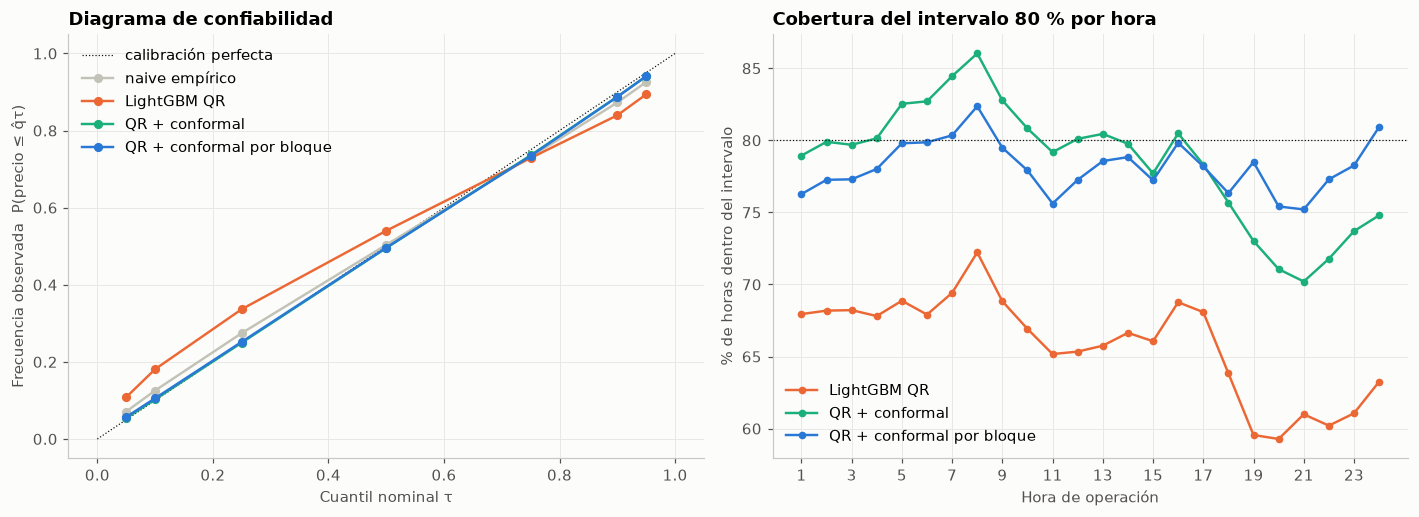

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=TINTA, lw=0.8, ls=":", label="calibración perfecta")
for k, p in METODOS.items():
    emp = [np.mean(p["precio"] <= p[c]) for c in QCOLS]
    ax.plot(QS, emp, marker="o", ms=5, color=COLOR_M[k], label=k)
ax.set_title("Diagrama de confiabilidad")
ax.set_xlabel("Cuantil nominal τ")
ax.set_ylabel("Frecuencia observada  P(precio ≤ q̂τ)")
ax.legend(loc="upper left")

ax = axes[1]
for k in ["LightGBM QR", "QR + conformal", FINAL]:
    p = METODOS[k]
    cob = ((p["precio"] >= p["q10"]) & (p["precio"] <= p["q90"])).groupby(p["hora"]).mean() * 100
    ax.plot(cob.index, cob.values, marker="o", ms=4, color=COLOR_M[k], label=k)
ax.axhline(80, color=TINTA, lw=0.8, ls=":")
ax.set_title("Cobertura del intervalo 80 % por hora")
ax.set_xlabel("Hora de operación")
ax.set_ylabel("% de horas dentro del intervalo")
ax.set_xticks(range(1, 25, 2))
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

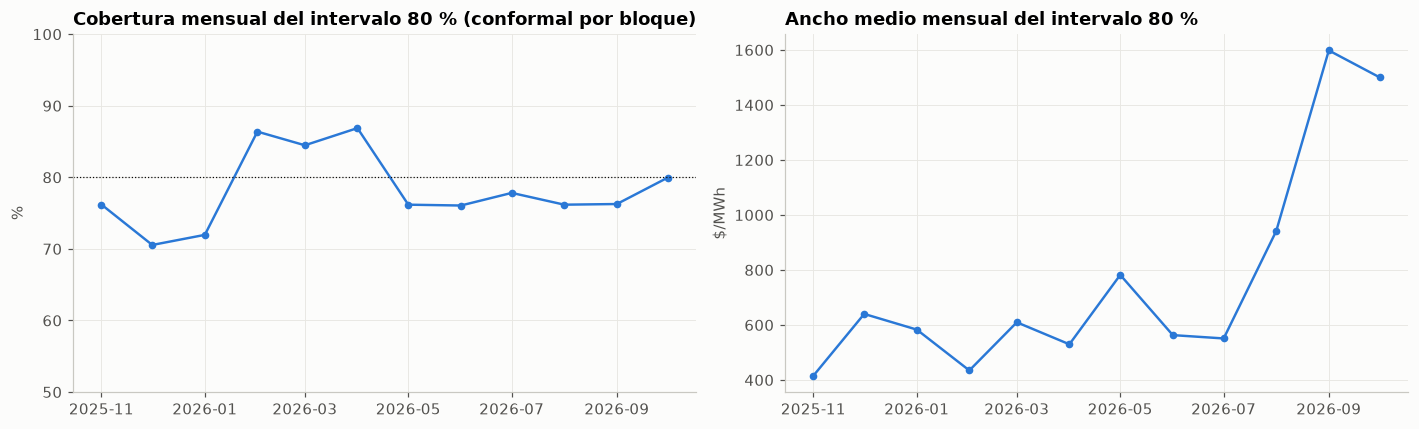

In [9]:
p = METODOS[FINAL]
mens = p.assign(mes=p.timestamp.dt.to_period("M")).groupby("mes").apply(
    lambda g: pd.Series({"cobertura": 100 * np.mean((g.precio >= g.q10) & (g.precio <= g.q90)),
                         "ancho": np.mean(g.q90 - g.q10)}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = mens.index.to_timestamp()
axes[0].plot(x, mens["cobertura"], color=AZUL, marker="o", ms=4)
axes[0].axhline(80, color=TINTA, lw=0.8, ls=":")
axes[0].set_ylim(50, 100)
axes[0].set_title("Cobertura mensual del intervalo 80 % (conformal por bloque)")
axes[0].set_ylabel("%")
axes[1].plot(x, mens["ancho"], color=AZUL, marker="o", ms=4)
axes[1].set_title("Ancho medio mensual del intervalo 80 %")
axes[1].set_ylabel("$/MWh")
plt.tight_layout()
plt.show()

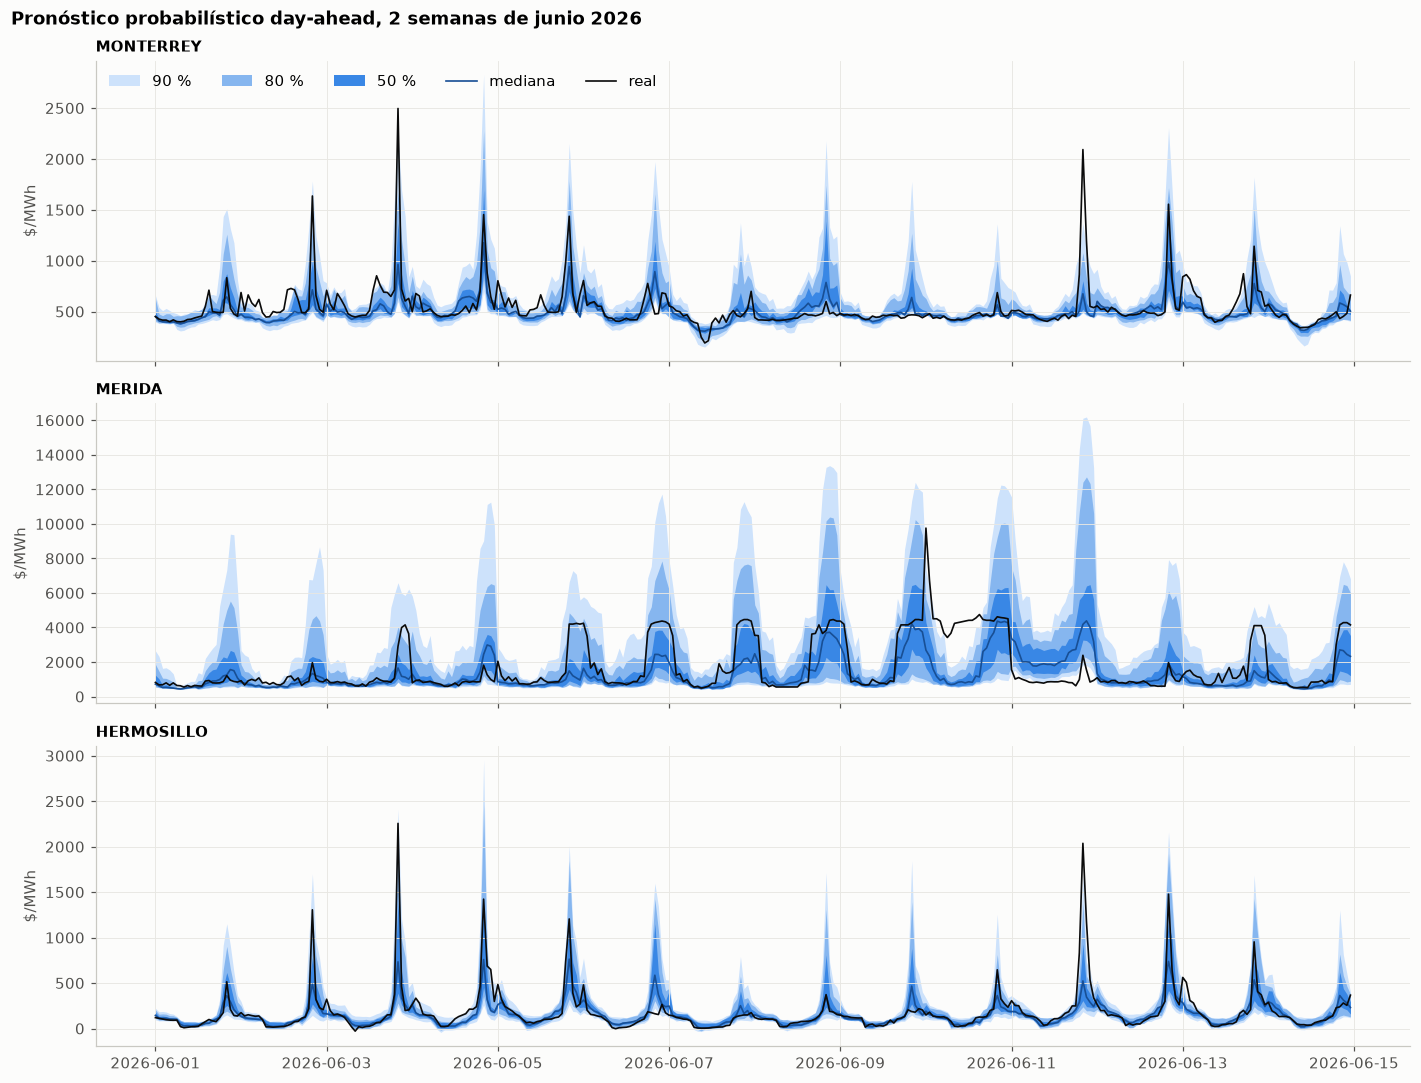

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
ini = pd.Timestamp("2026-06-01")
w = p[(p.timestamp >= ini) & (p.timestamp < ini + pd.Timedelta(days=14))]
for ax, z in zip(axes, ZONAS_FOCO):
    g = w[w.clave == z]
    ax.fill_between(g.timestamp, g.q05, g.q95, color="#cde2fb", lw=0, label="90 %")
    ax.fill_between(g.timestamp, g.q10, g.q90, color="#86b6ef", lw=0, label="80 %")
    ax.fill_between(g.timestamp, g.q25, g.q75, color="#3987e5", lw=0, label="50 %")
    ax.plot(g.timestamp, g.q50, color="#184f95", lw=1.1, label="mediana")
    ax.plot(g.timestamp, g.precio, color=TINTA, lw=1.1, label="real")
    ax.set_title(z, fontsize=10)
    ax.set_ylabel("$/MWh")
axes[0].legend(loc="upper left", ncol=5)
fig.suptitle("Pronóstico probabilístico day-ahead, 2 semanas de junio 2026", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Caso de uso: alerta de picos

Pico = precio por encima del percentil 95 histórico de la zona (calculado antes del periodo de prueba).
Se emite alerta para una hora si el cuantil 90 pronosticado supera ese umbral, y se compara contra una regla ingenua
(alertar si ayer a la misma hora hubo pico) y contra usar solo el pronóstico puntual (q50).

In [11]:
UMBRAL = df[df.timestamp < CAL_INICIO].groupby("clave")["precio"].quantile(0.95)

def alerta(p, columna):
    real = p["precio"] > p["clave"].map(UMBRAL)
    pred = p[columna] > p["clave"].map(UMBRAL)
    vp = (real & pred).sum()
    return pd.Series({"picos reales": real.sum(), "alertas": pred.sum(),
                      "precisión": vp / max(pred.sum(), 1), "recall": vp / max(real.sum(), 1)})

p = METODOS[FINAL].merge(feat[["clave", "timestamp", "y_lag24"]], on=["clave", "timestamp"])
p["naive_ayer"] = inv(p["y_lag24"], p["clave"], MEDIANA)
reglas = {"naive (pico ayer)": "naive_ayer", "puntual (q50)": "q50", "riesgo (q75)": "q75", "riesgo (q90)": "q90"}
tabla_alerta = pd.DataFrame({k: alerta(p, c) for k, c in reglas.items()}).T
tabla_alerta["F1"] = 2 * tabla_alerta["precisión"] * tabla_alerta["recall"] / (tabla_alerta["precisión"] + tabla_alerta["recall"])
tabla_alerta.round(3)

,picos reales,alertas,precisión,recall,F1
naive (pico ayer),3893.0,3887.0,0.498,0.497,0.497
puntual (q50),3893.0,1426.0,0.659,0.241,0.353
riesgo (q75),3893.0,3598.0,0.564,0.521,0.542
riesgo (q90),3893.0,6828.0,0.423,0.743,0.539


In [12]:
filas = []
for z, g in p.groupby("clave"):
    for k, c in [("naive (pico ayer)", "naive_ayer"), ("riesgo (q90)", "q90")]:
        a = alerta(g, c)
        filas.append({"zona": z, "regla": k, "recall": a["recall"], "precisión": a["precisión"]})
pd.DataFrame(filas).pivot(index="zona", columns="regla").round(2)

recall                      precisión             
regla          naive (pico ayer) riesgo (q90) naive (pico ayer) riesgo (q90)
zona                                                                        
ACAPULCO                    0.45         0.72              0.45         0.41
AGUASCALIENTES              0.45         0.70              0.45         0.39
GUADALAJARA                 0.46         0.72              0.46         0.38
HERMOSILLO                  0.46         0.76              0.46         0.39
MERIDA                      0.55         0.76              0.55         0.45
MONTERREY                   0.49         0.72              0.49         0.42
PUEBLA                      0.53         0.79              0.53         0.46
QUERETARO                   0.44         0.69              0.44         0.38

## 6. Guardar

In [13]:
salida = METODOS[FINAL][["clave", "timestamp", "precio", *QCOLS]]
salida.to_parquet(OUT / "pronostico_cuantiles.parquet", index=False)
resumen.round(3).to_csv(OUT / "metricas_probabilisticas.csv")
por_zona.round(3).to_csv(OUT / "metricas_probabilisticas_zona.csv")
tabla_alerta.round(3).to_csv(OUT / "alerta_picos.csv")
print("Guardado en", OUT.resolve())

Guardado en C:\Users\uriel\Documents\Data Science Proyects\Series_de_tiempo\resultados


## Conclusiones

- **Calibración (cobertura vs nominal):** el LightGBM cuantílico sin corregir es **sobreconfiado**: el intervalo 80 % cubre solo 65.8 % y el de 90 % cubre 78.5 %.
  En el diagrama de confiabilidad la cola inferior es la más sesgada: el precio cae por debajo de q05 y q10 el 11 % y el 18 % de las veces (en vez de 5 % y 10 %). La cola superior también se queda corta: el precio rebasa q95 el 10 % de las veces, el doble de lo esperado.
  Tras la calibración conformal por bloque las coberturas quedan en **78.2 % y 88.4 %**, a menos de 2 puntos del nominal, y los 7 cuantiles caen prácticamente sobre la diagonal.
- **Efecto de la corrección conformal:** ensancha el intervalo 80 % de 553 a 765 $/MWh (+38 %), pero ese ancho extra es necesario: el Winkler baja 4.8 % (80 %) y 9.7 % (90 %), y la pinball pasa de 87.1 a 84.2.
  La mediana no cambia (MAE p50 ≈ 268, en línea con los 264.8 del LightGBM puntual del notebook 03), así que el pronóstico probabilístico no sacrifica precisión puntual.
  Separar los residuos por bloque horario aplana la cobertura a lo largo del día: con la versión global oscila entre 70 % (rampa de 19–22 h) y 86 % (madrugada, 5–8 h); por bloque queda entre ~75 % y 82 %.
  Frente al naive empírico, el modelo final reduce la pinball 27 % (24–29 % en cada zona) con intervalos más angostos (765 vs 960 $/MWh) y mejor cobertura.
- **Dónde los intervalos son más anchos / fallan más:**
  - *Por zona:* **Mérida** domina el error (pinball 230, intervalo 80 % de 2,164 $/MWh, ~4–6 veces Hermosillo). Sus precios forman mesetas de ~4,000 $/MWh que duran horas y el modelo a veces las anticipa con bandas de hasta 16,000 que no se materializan, y otras veces se queda debajo de la meseta (p. ej. 10–11 jun 2026). La cobertura por zona sí es pareja (77–79 %), lo que confirma que la calibración funciona en todas.
  - *Por hora:* la cobertura más baja está en la rampa nocturna (19–22 h) y alrededor de las 11 h.
  - *En el tiempo:* hay subcobertura en nov 2025 – ene 2026 (70–76 %) y sobrecobertura en feb–abr 2026 (84–87 %). La ventana de 90 días reacciona tarde a los cambios de régimen. De ago a oct 2026 el ancho se dispara (≈ 940–1,600 $/MWh, contra 400–800 antes) por la mayor volatilidad, y aun así la cobertura se mantiene en 76–80 %.
  - *Picos aislados:* en Monterrey y Hermosillo el modelo acierta *cuándo* puede haber un pico (las bandas se abren a la hora correcta), pero los picos extremos (> 2,000 $/MWh) rebasan el q95.
- **Valor de negocio de la alerta de picos:** usar solo el pronóstico puntual (q50) es engañoso: es preciso (66 %), pero **deja pasar 3 de cada 4 picos** (recall 0.24).
  La alerta con q90 detecta el **74 %** de los picos, contra 50 % de la regla naive (69–79 % según la zona, contra 44–55 %), a cambio de más falsas alarmas (precisión 0.42, ~1.75 alertas por pico real).
  La alerta con q75 ofrece el mejor equilibrio (F1 0.54, precisión 0.56, recall 0.52). El cuantil para alertar se elige según el costo relativo de cada error: si quedarse sin cobertura ante un pico cuesta más que una cobertura innecesaria, conviene q90; si no, q75.
- **Siguientes pasos:**
  - Variables exógenas (temperatura, demanda pronosticada, disponibilidad de generación/transmisión), sobre todo para la congestión de Mérida.
  - Conformal adaptativo (ACI) o ventanas más cortas o ponderadas, para reaccionar más rápido a los cambios de régimen.
  - Reducir el 36.6 % de cuantiles cruzados con un modelo multi-cuantil o con restricciones de monotonicidad, en lugar de ordenarlos a posteriori.
  - Dashboard con las bandas y la alerta de picos por zona.